# 実験8 (ex008): LIBSVM ijcnn1 二値ロジスティック回帰 ($N=3$, 50ラウンド, 同一設定・最適設定)

論文 Table 3・Figure 7（$N=3$, 50ラウンド）に基づき、同一設定（$\alpha=0.001$）と最適設定の両方で全 11 手法を 10 シード比較します。

In [1]:
import os
import torch
import pandas as pd
from model import verify_batched_lr_equivalence
from utils import (
    DEFAULT_SEEDS, load_and_partition_ijcnn1, run_multiseed_ijcnn1_lr,
    plot_ijcnn1_curves, plot_ijcnn1_boxplot, plot_filtered_results,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用デバイス: {device}")

使用デバイス: cuda


In [2]:
clients, packed_clients, X_train, y_train, X_test, y_test = load_and_partition_ijcnn1(
    data_dir="../datasets", num_clients=3, beta=0.1, train_ratio=0.75, seed=42, device=device
)
max_diff = verify_batched_lr_equivalence(clients, packed_clients, tau=5, batch_size=100, lr=0.001, device=device)
print(f"ijcnn1 train={X_train.shape}, test={X_test.shape} | 並列SGD最大誤差: {max_diff:.3e}")

ijcnn1 train=torch.Size([143760, 22]), test=torch.Size([47921, 22]) | 並列SGD最大誤差: 0.000e+00


In [3]:
configs_same = [
    {"name": "FedAvg",        "algo": "FedAvg",        "lr": 0.001},
    {"name": "FedSSO",        "algo": "FedSSO",        "lr": 0.001, "eta": 1.0},
    {"name": "FedSSO-NAQ",    "algo": "FedSSO-NAQ",    "lr": 0.001, "eta": 1.0, "mu": 0.30},
    {"name": "FedSSO-MoQ",    "algo": "FedSSO-MoQ",    "lr": 0.001, "eta": 1.0, "mu": 0.30},
    {"name": "FedSSO-AdaNAQ", "algo": "FedSSO-AdaNAQ", "lr": 0.001, "eta": 1.0, "max_mu": 0.40},
    {"name": "FedSSO-AdaMoQ", "algo": "FedSSO-AdaMoQ", "lr": 0.001, "eta": 1.0, "max_mu": 0.40},
    {"name": "FedSSO-LBFGS",  "algo": "FedSSO-LBFGS",  "lr": 0.001, "eta": 1.0, "m_size": 10},
    {"name": "FedSSO-LNAQ",   "algo": "FedSSO-LNAQ",   "lr": 0.001, "eta": 1.0, "max_mu": 0.40, "m_size": 10},
    {"name": "FedSSO-LMoQ",   "algo": "FedSSO-LMoQ",   "lr": 0.001, "eta": 1.0, "max_mu": 0.40, "m_size": 10},
    {"name": "FedSSO-MLNAQ",  "algo": "FedSSO-MLNAQ",  "lr": 0.001, "eta": 1.0, "max_mu": 0.40},
    {"name": "FedSSO-MLMoQ",  "algo": "FedSSO-MLMoQ",  "lr": 0.001, "eta": 1.0, "max_mu": 0.40},
]
configs_opt = [{"name": "FedAvg", "algo": "FedAvg", "lr": 0.1}] + configs_same[1:]

sum_same, ps_same, curves_same = run_multiseed_ijcnn1_lr(
    configs_same, packed_clients, X_train, y_train, X_test, y_test, setting_tag="same",
    seeds=DEFAULT_SEEDS, rounds=50, save_log_dir="../datasets/ex008_ijcnn1_lr_logs",
    history_csv_path="../datasets/ex008_ijcnn1_lr_same_history.csv",
)
sum_opt, ps_opt, curves_opt = run_multiseed_ijcnn1_lr(
    configs_opt, packed_clients, X_train, y_train, X_test, y_test, setting_tag="opt",
    seeds=DEFAULT_SEEDS, rounds=50, save_log_dir="../datasets/ex008_ijcnn1_lr_logs",
    history_csv_path="../datasets/ex008_ijcnn1_lr_opt_history.csv",
)
sum_same.to_csv("../datasets/ex008_ijcnn1_lr_same_summary.csv", index=False)
ps_same.to_csv("../datasets/ex008_ijcnn1_lr_same_per_seed.csv", index=False)
sum_opt.to_csv("../datasets/ex008_ijcnn1_lr_opt_summary.csv", index=False)
ps_opt.to_csv("../datasets/ex008_ijcnn1_lr_opt_per_seed.csv", index=False)
sum_opt

,Setting,Algorithm,Comm_Per_Iter,Loss_Ave,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,MaxAcc_Ave,Clip_Ave,Reset_Ave,Server_Time_ms,Server_Mem_MB,Bytes@0.91,Reach@0.85,Iter@0.85,Comm@0.85,Reach@0.90,Iter@0.90,Comm@0.90,Reach@0.91,Iter@0.91,Comm@0.91,Reach@0.92,Iter@0.92,Comm@0.92
0,opt,FedAvg,1.00,0.215132,0.915281,0.915309,0.916216,0.914380,0.000528,0.915465,0.0,0.0,0.007372,0.000175,7360,10/10,2.4,2.4,10/10,3.8,3.8,10/10,20.0,20.0,0/10,NaN,NaN
1,opt,FedSSO,1.00,0.205297,0.919467,0.921506,0.923812,0.904635,0.005444,0.924724,0.5,0.5,0.475635,0.008774,1766,10/10,1.2,1.2,10/10,2.0,2.0,10/10,4.8,4.8,9/10,12.6,12.6
2,opt,FedSSO-NAQ,1.98,0.202206,0.922900,0.922372,0.927485,0.919826,0.002093,0.926583,0.3,0.2,0.623469,0.009125,2944,10/10,1.2,1.4,10/10,2.0,3.0,10/10,4.5,8.0,10/10,13.2,25.4
3,opt,FedSSO-MoQ,1.00,0.197081,0.920131,0.919868,0.925127,0.916028,0.002422,0.925348,0.3,0.2,0.755609,0.009300,1914,10/10,1.2,1.2,10/10,2.0,2.0,10/10,5.2,5.2,10/10,17.7,17.7
4,opt,FedSSO-AdaNAQ,1.98,0.245290,0.923290,0.922184,0.931387,0.918282,0.003952,0.928453,0.8,0.3,0.718640,0.009125,2870,10/10,1.2,1.4,10/10,2.0,3.0,10/10,4.4,7.8,10/10,12.3,23.6
5,opt,FedSSO-AdaMoQ,1.00,0.209299,0.919467,0.920505,0.924522,0.904760,0.005580,0.925002,0.3,0.3,0.482522,0.009300,1950,10/10,1.2,1.2,10/10,2.0,2.0,10/10,5.3,5.3,10/10,19.1,19.1
6,opt,FedSSO-LBFGS,1.00,0.201236,0.922479,0.922247,0.928424,0.914067,0.003513,0.926725,0.2,0.1,0.997336,0.004211,1619,10/10,1.2,1.2,10/10,2.0,2.0,10/10,4.4,4.4,10/10,11.1,11.1
7,opt,FedSSO-LNAQ,1.98,0.304665,0.917103,0.920432,0.931074,0.901129,0.010260,0.928564,0.2,0.1,1.018056,0.004562,2723,10/10,1.2,1.4,10/10,2.0,3.0,10/10,4.2,7.4,10/10,11.4,21.8
8,opt,FedSSO-LMoQ,1.00,0.201464,0.920999,0.921944,0.925753,0.911980,0.003448,0.924697,0.1,0.0,1.030414,0.004738,1656,10/10,1.2,1.2,10/10,2.0,2.0,10/10,4.5,4.5,10/10,16.5,16.5
9,opt,FedSSO-MLNAQ,1.98,0.200002,0.920346,0.919565,0.927798,0.916592,0.003443,0.921615,9.4,0.0,0.474355,0.001404,2723,10/10,1.2,1.4,10/10,2.0,3.0,10/10,4.2,7.4,5/10,13.4,25.8


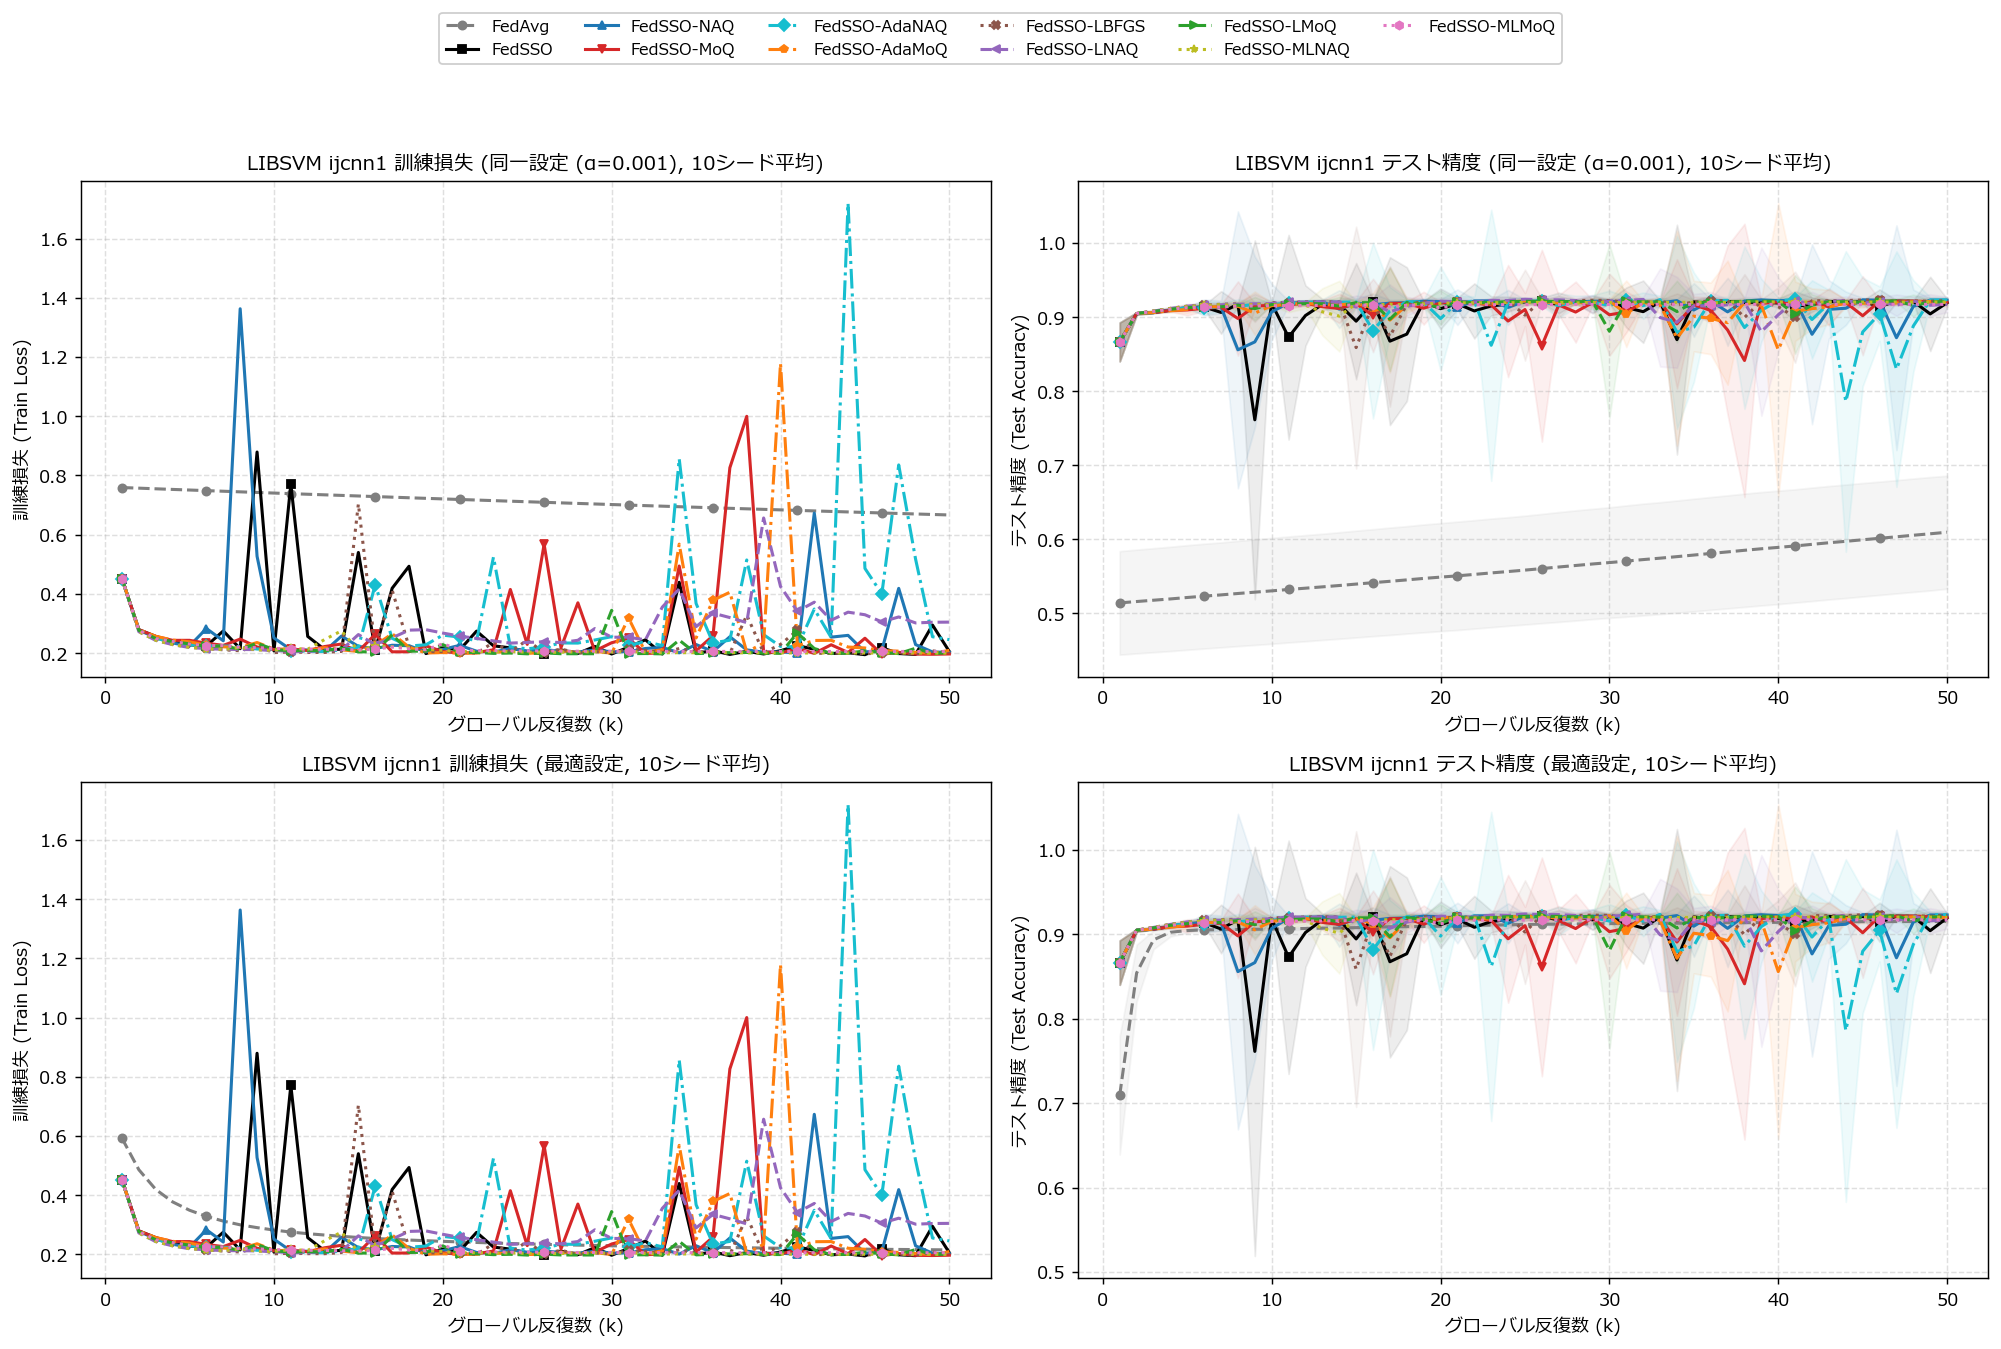

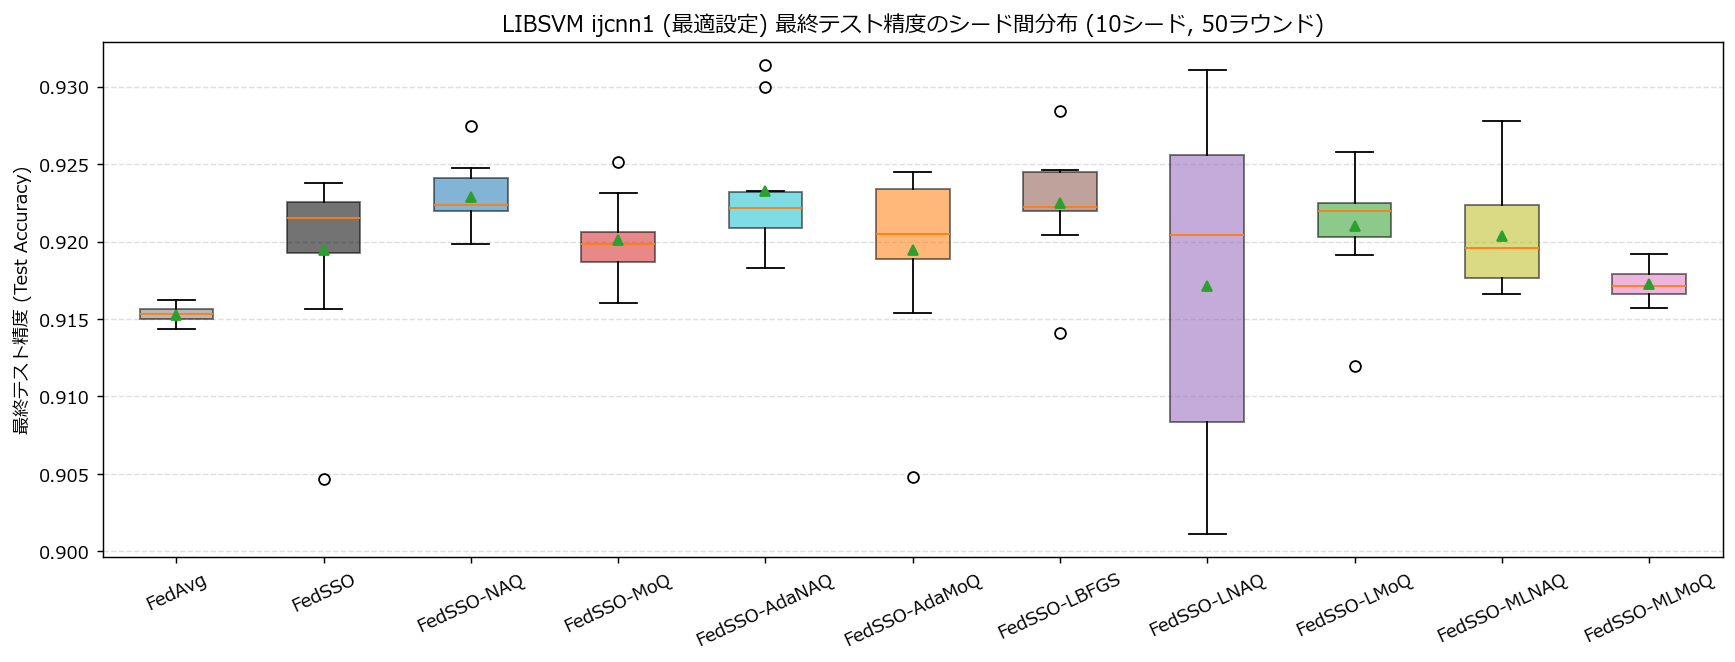

In [4]:
os.makedirs("../report/img", exist_ok=True)
plot_ijcnn1_curves(curves_same, curves_opt, save_path="../report/img/ex008_ijcnn1_lr_curves.png")
plot_ijcnn1_boxplot(ps_opt, save_path="../report/img/ex008_ijcnn1_lr_boxplot.png")

## 特定のシード値・アルゴリズムに絞ったグラフ表示

保存済みの全履歴 CSV（`../datasets/ex008_ijcnn1_lr_opt_history.csv`）から任意のアルゴリズム・シード値だけを指定して再描画できます。 `SELECTED_SEEDS = None` のときは全シード平均のみを自動表示・出力します。

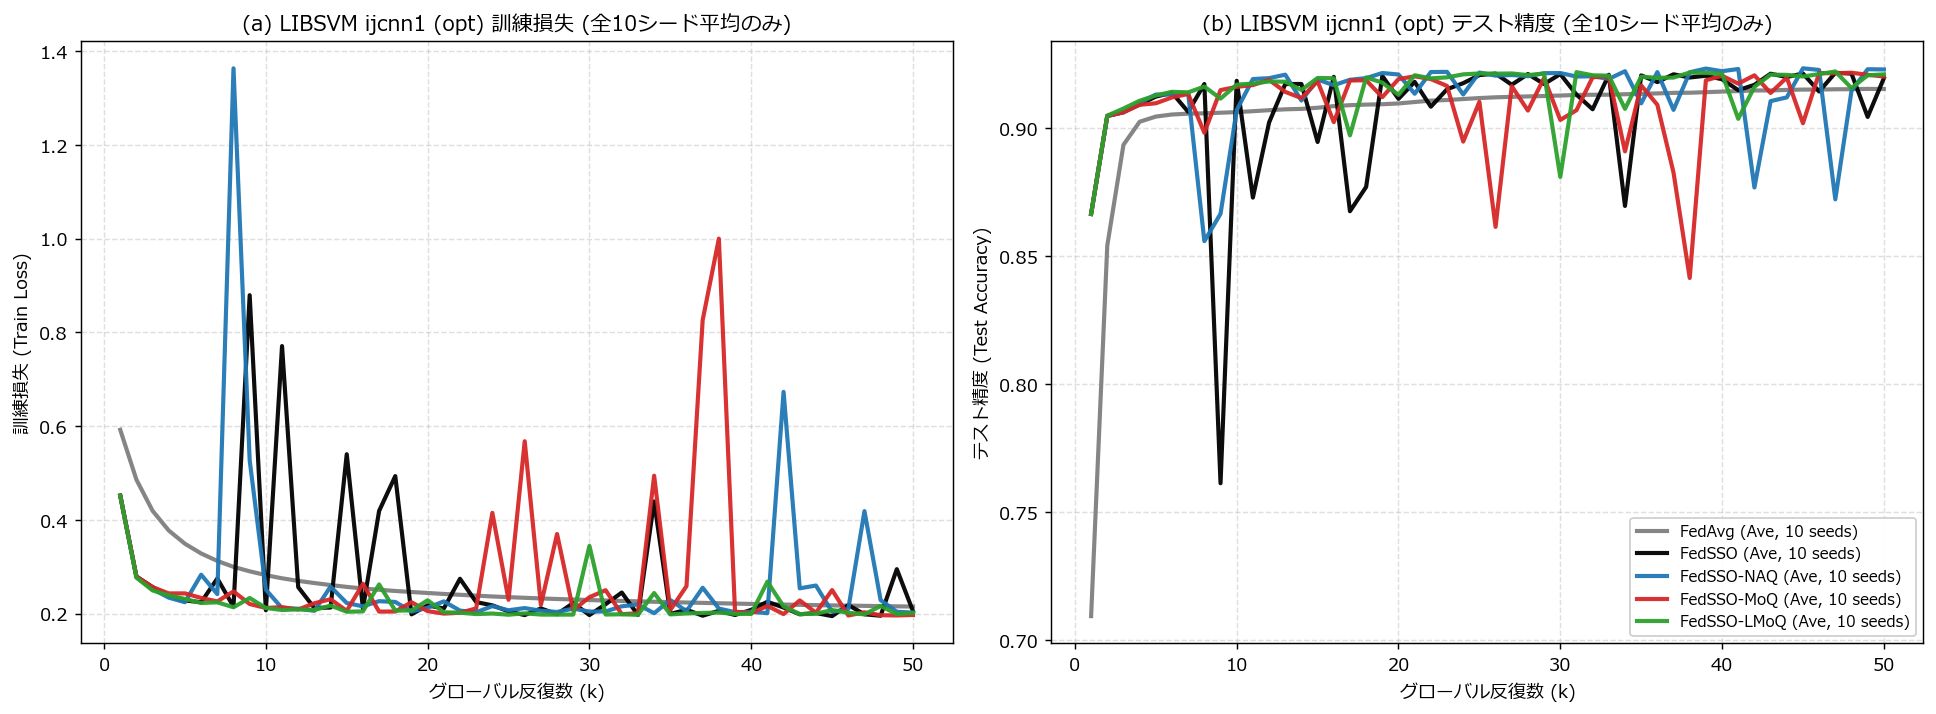

,Algorithm,Seeds,Round,Comm_Round,Train_Loss_Ave,Test_Acc_Ave
0,FedAvg,10,50,50.0,0.215132,0.915281
1,FedSSO,10,50,50.0,0.205297,0.919467
2,FedSSO-NAQ,10,50,99.0,0.202206,0.922900
3,FedSSO-MoQ,10,50,50.0,0.197081,0.920131
4,FedSSO-LMoQ,10,50,50.0,0.201464,0.920999


In [5]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示
# 利用可能なアルゴリズム:
#   ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-AdaMoQ",
#    "FedSSO-LBFGS", "FedSSO-LNAQ", "FedSSO-LMoQ", "FedSSO-MLNAQ", "FedSSO-MLMoQ"]
#   None を指定すると全手法が対象になります
# 利用可能なシード値: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] (None で全シード対象)
SELECTED_ALGOS = ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-LMoQ"]
SELECTED_SEEDS = None       # None で全10シード対象（例: [42, 46] で特定シードに絞り込み）
X_AXIS_MODE = "round"       # "round" (反復数) または "comm" (累積通信ラウンド数)
SHOW_MEAN_CURVE = True      # 複数シード指定時に平均太線を重ね描きするか
PLOT_MEAN_ONLY = "auto"     # "auto": SELECTED_SEEDS=None 時に平均線のみ描画 / True: 平均のみ / False: 個別シードも描画
TABLE_MEAN_ONLY = "auto"    # "auto": SELECTED_SEEDS=None 時に平均のみの行を出力 / True: 平均のみ / False: シード別に出力

filtered_df = plot_filtered_results(
    selected_algos=SELECTED_ALGOS,
    selected_seeds=SELECTED_SEEDS,
    setting_tag="opt",
    history_csv_path="../datasets/ex008_ijcnn1_lr_opt_history.csv",
    log_dir="../datasets/ex008_ijcnn1_lr_logs",
    x_axis=X_AXIS_MODE,
    show_mean=SHOW_MEAN_CURVE,
    plot_mean_only=PLOT_MEAN_ONLY,
    table_mean_only=TABLE_MEAN_ONLY,
)
filtered_df